# 04 Exploratory Data Analysis

This notebook performs exploratory data analysis (EDA) on the **cleaned** BotPrint event dataset.

**Purpose:** understand behavioural differences between Human and Bot sessions across mouse movement, keyboard typing, clicking, scrolling, session duration, idle time, navigation patterns, event frequency, and behavioural variability.

**Important constraints:**
- Uses `dataset/processed/cleaned_events.csv` (original raw dataset is not modified).
- Visual differences are descriptive only; we do **not** claim that any feature can distinguish humans and bots based on visual inspection alone.
- Sample sizes are reported for every comparison.
- Session-level conclusions are drawn from **session-level aggregates**, not by treating individual events as independent sessions.
- Bot subtypes (CoordinatedBot, RandomBot, MimicBot) are compared descriptively where sufficient observations exist.
- No machine learning is performed.

In [1]:
# 1. Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120

# Resolve project root robustly (kernel cwd is notebooks/)
_here = Path.cwd()
_root = _here
for _ in range(5):
    if (_root / 'README.md').exists() and (_root / 'dataset').exists():
        break
    _root = _root.parent
PROJECT_ROOT = _root
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

DATA_PATH = PROJECT_ROOT / 'dataset' / 'processed' / 'cleaned_events.csv'
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
ANALYSIS_DIR = PROJECT_ROOT / 'reports' / 'analysis'
FIG_DIR.mkdir(parents=True, exist_ok=True)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

print('Project root:', PROJECT_ROOT)
print('Data path exists:', DATA_PATH.exists())


Project root: C:\My KS\Research\BotPrint-Research
Data path exists: True


In [2]:
# 2. Load cleaned dataset
df = pd.read_csv(DATA_PATH)
df['Timestamp_dt'] = pd.to_datetime(df.get('Timestamp_dt'), errors='coerce')
print('Shape:', df.shape)
print('Unique sessions:', df['SessionID'].nunique())
print('Event types:', sorted(df['EventType'].dropna().unique().tolist()))
print('\nUserType counts (events):')
print(df['UserType'].value_counts(dropna=False).to_string())
print('\nBotType counts (events):')
print(df['BotType'].value_counts(dropna=False).to_string())


Shape: (1196, 36)
Unique sessions: 24
Event types: ['click', 'field_interaction', 'form_submit', 'keypress', 'mousemove', 'scroll', 'session_end', 'session_start']

UserType counts (events):
UserType
Human    665
Bot      531

BotType counts (events):
BotType
NaN               665
CoordinatedBot    325
RandomBot         139
MimicBot           67


## 3. Sample sizes

EDA interpretations depend on how much data supports each group. We report **event-level** and **session-level** sample sizes because session-level conclusions must be based on sessions, not individual events.

In [3]:
# 3. Sample sizes
event_n = df.groupby('UserType').size().rename('n_events')
sess_n = df.groupby('UserType')['SessionID'].nunique().rename('n_sessions')
sample_hb = pd.concat([event_n, sess_n], axis=1).reset_index()
print('Human vs Bot sample sizes:')
print(sample_hb.to_string(index=False))

bot_df = df[df['UserType'] == 'Bot'].copy()
bot_event_n = bot_df.groupby('BotType').size().rename('n_events')
bot_sess_n = bot_df.groupby('BotType')['SessionID'].nunique().rename('n_sessions')
sample_bot = pd.concat([bot_event_n, bot_sess_n], axis=1).reset_index()
print('\nBot subtype sample sizes (Bot sessions only):')
print(sample_bot.to_string(index=False))

sample_hb.to_csv(ANALYSIS_DIR / 'eda_sample_sizes_human_bot.csv', index=False)
sample_bot.to_csv(ANALYSIS_DIR / 'eda_sample_sizes_bot_types.csv', index=False)

# Events per session distribution (context for session-level analyses)
sess_counts = df.groupby(['SessionID','UserType','BotType'], dropna=False).size().reset_index(name='n_events')
print('\nEvents per session summary by UserType:')
print(sess_counts.groupby('UserType')['n_events'].describe().round(2).to_string())


Human vs Bot sample sizes:
UserType  n_events  n_sessions
     Bot       531          15
   Human       665           9

Bot subtype sample sizes (Bot sessions only):
       BotType  n_events  n_sessions
CoordinatedBot       325           5
      MimicBot        67           5
     RandomBot       139           5

Events per session summary by UserType:
          count   mean    std   min   25%   50%    75%    max
UserType                                                     
Bot        15.0  35.40  26.15  10.0  13.5  19.0   63.5   72.0
Human       9.0  73.89  95.59   1.0   3.0  16.0  118.0  281.0


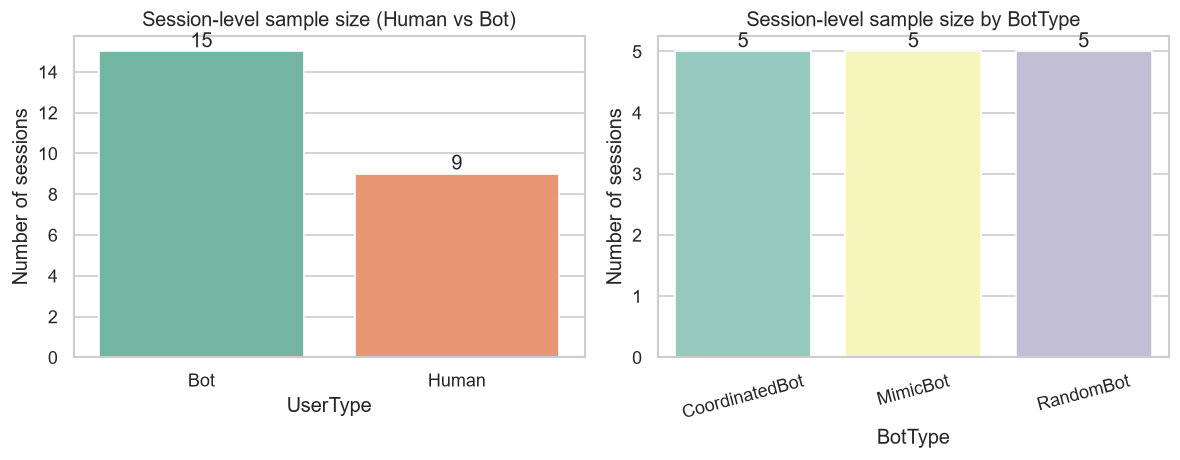

In [4]:
# 3b. Visualise sample sizes and event distribution
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(data=sample_hb, x='UserType', y='n_sessions', ax=axes[0], palette='Set2')
axes[0].set_title('Session-level sample size (Human vs Bot)')
axes[0].set_ylabel('Number of sessions')
for c in axes[0].containers:
    axes[0].bar_label(c)

sns.barplot(data=sample_bot, x='BotType', y='n_sessions', ax=axes[1], palette='Set3')
axes[1].set_title('Session-level sample size by BotType')
axes[1].set_ylabel('Number of sessions')
axes[1].tick_params(axis='x', rotation=15)
for c in axes[1].containers:
    axes[1].bar_label(c)
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_sample_sizes.png', bbox_inches='tight')
plt.show()


**Interpretation:** Human and Bot groups have different session counts, and each bot subtype has a small number of sessions. Small session-level samples limit how confidently we can generalise observed patterns; subtype comparisons are therefore descriptive and exploratory.

## 4. Session-level aggregation helper

We build session-level summaries for duration, idle time, navigation, event frequency, and variability. These aggregates are used for session-level comparisons so that sessions (not events) are the unit of analysis.

In [5]:
# 4. Session-level aggregates
def iqr(x):
    x = pd.Series(x).dropna()
    return x.quantile(0.75) - x.quantile(0.25) if len(x) else np.nan

def cv(x):
    x = pd.Series(x).dropna()
    m = x.mean()
    return (x.std(ddof=1) / m) if (len(x) > 1 and pd.notna(m) and m != 0) else np.nan

agg = df.groupby(['SessionID','UserType','BotType'], dropna=False).agg(
    n_events=('EventType','size'),
    session_duration_ms=('SessionDurationMs','max'),
    elapsed_max_ms=('ElapsedMs','max'),
    idle_mean_ms=('IdleMs','mean'),
    idle_median_ms=('IdleMs','median'),
    idle_std_ms=('IdleMs','std'),
    navigation_events=('EventType', lambda s: int((s.astype(str).str.lower() == 'navigation').sum())),
    total_navigations=('NavigationCount','max'),
).reset_index()

# Prefer SessionDurationMs when present; fall back to max ElapsedMs
agg['duration_ms'] = agg['session_duration_ms'].fillna(agg['elapsed_max_ms'])
agg['events_per_second'] = agg['n_events'] / (agg['duration_ms'] / 1000.0).replace({0: np.nan})
print(agg[['SessionID','UserType','BotType','n_events','duration_ms','idle_mean_ms','events_per_second']].head().to_string(index=False))
agg.to_csv(ANALYSIS_DIR / 'eda_session_level_summary.csv', index=False)


                             SessionID UserType        BotType  n_events  duration_ms  idle_mean_ms  events_per_second
S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8    Human            NaN       118        38104    309.779661           3.096788
S-1710524c-4560-4abd-906c-6f336edff5de      Bot CoordinatedBot        56        31078    510.696429           1.801918
S-1f44b887-5413-4283-91dc-5ac39b63feff      Bot      RandomBot        12        18660    168.333333           0.643087
S-2510ce7a-5d0f-479d-89e2-a251a2e9a162      Bot      RandomBot        22        20055    215.318182           1.096983
S-28ae68f8-c6e5-44f9-8120-1385f632233c      Bot      RandomBot        18        18770    214.777778           0.958977


## 5. Event frequency

Event frequency is examined at the session level (events per session and events per second) to avoid treating individual events as independent sessions.

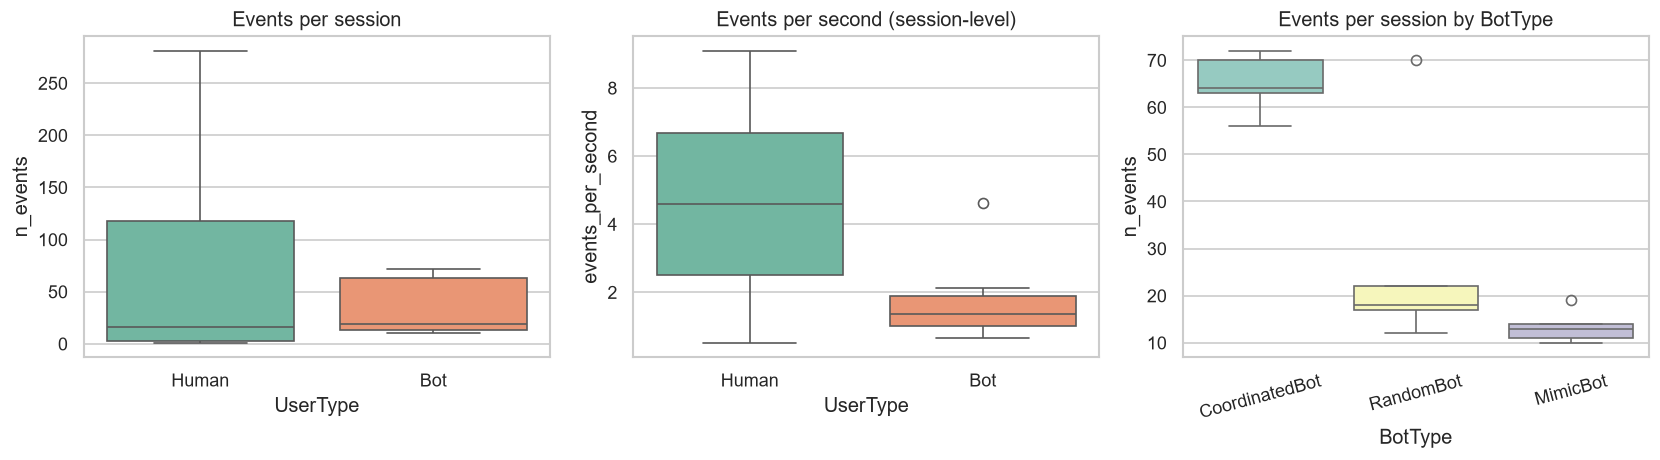

Event frequency summary (session-level):
         n_events                        events_per_second                     
            count median    mean     std             count median   mean    std
UserType                                                                       
Bot            15   19.0  35.400  26.153                15  1.355  1.621  0.958
Human           9   16.0  73.889  95.588                 8  4.581  4.646  3.203


In [6]:
# 5. Event frequency
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title in [
    (axes[0], 'n_events', 'Events per session'),
    (axes[1], 'events_per_second', 'Events per second (session-level)'),
    (axes[2], 'n_events', 'Events per session by BotType'),
]:
    if col == 'n_events' and title.endswith('BotType'):
        d = agg[agg['UserType']=='Bot']
        sns.boxplot(data=d, x='BotType', y=col, ax=ax, palette='Set3')
        ax.tick_params(axis='x', rotation=15)
    else:
        sns.boxplot(data=agg, x='UserType', y=col, ax=ax, palette='Set2')
    ax.set_title(title)
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_event_frequency.png', bbox_inches='tight')
plt.show()

print('Event frequency summary (session-level):')
print(agg.groupby('UserType')[['n_events','events_per_second']].agg(['count','median','mean','std']).round(3).to_string())


**Interpretation:** Session-level event frequency summaries describe how active sessions are. Any apparent separation between groups is descriptive; it should not be interpreted as proof that event frequency alone can distinguish humans from bots, especially given the limited session counts.

## 6. Mouse movement behaviour

Mouse behaviour is analysed using mouse-move events (`Speed`, `Acceleration`, `DX`, `DY`) where available. Event-level distributions are shown for context, and session-level variability is summarised separately.

Mousemove events: 393
Sessions with mousemove: 18
By UserType (events/sessions):
          n_events  n_sessions
UserType                      
Bot             24          10
Human          369           8


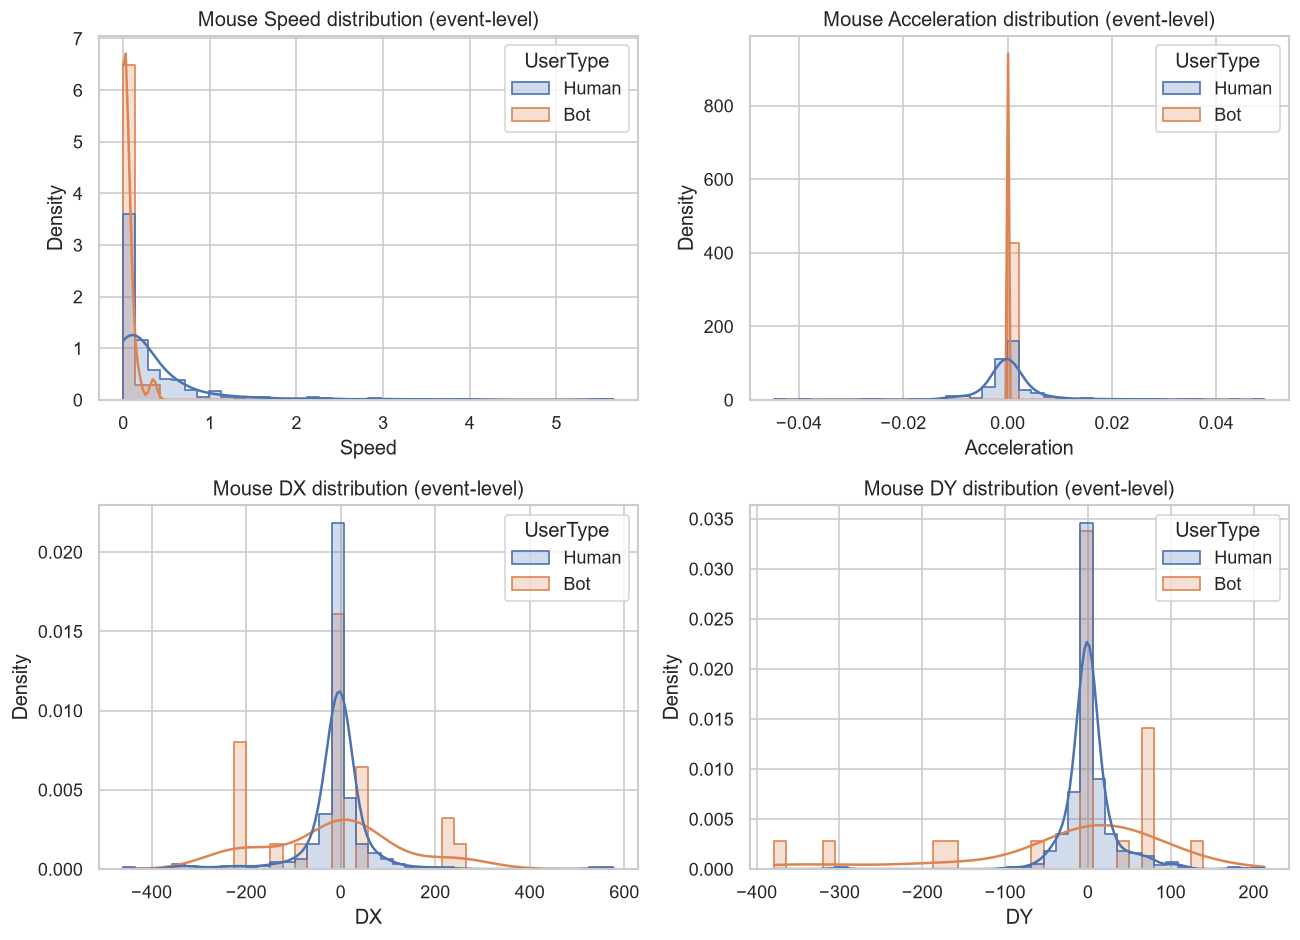

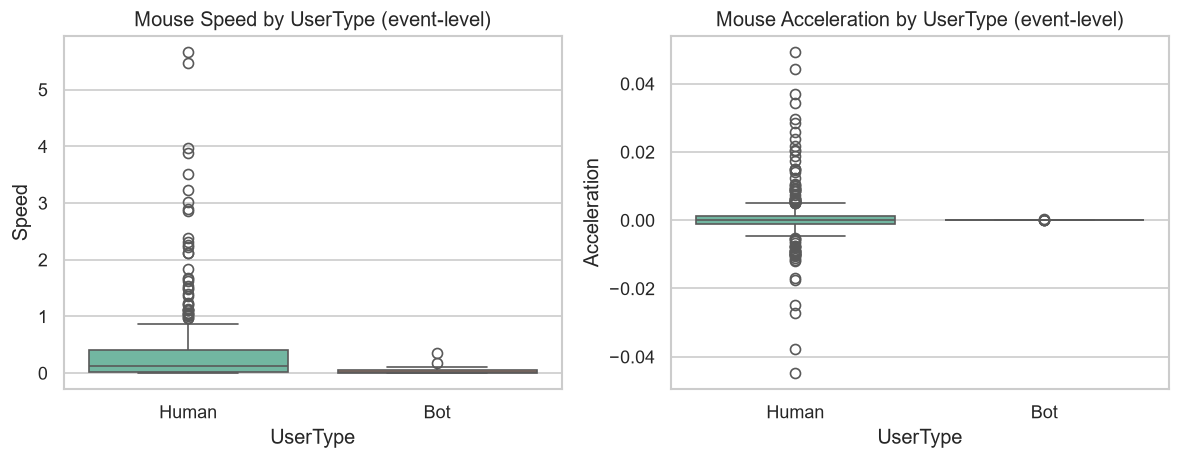


Session-level mouse summary:
          n_mouse  mouse_speed_median  mouse_speed_iqr  mouse_speed_cv
UserType                                                              
Bot           2.0               0.026            0.024           1.414
Human        30.0               0.146            0.393           1.689


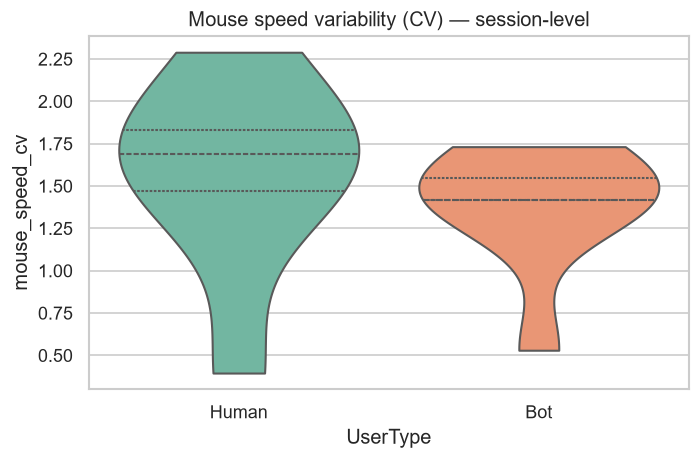

In [7]:
# 6. Mouse movement
mouse = df[df['EventType'].astype(str).str.lower().eq('mousemove')].copy()
for c in ['Speed','Acceleration','DX','DY','X','Y']:
    if c in mouse.columns:
        mouse[c] = pd.to_numeric(mouse[c], errors='coerce')
print('Mousemove events:', len(mouse))
print('Sessions with mousemove:', mouse['SessionID'].nunique())
print('By UserType (events/sessions):')
print(mouse.groupby('UserType').agg(n_events=('SessionID','size'), n_sessions=('SessionID','nunique')).to_string())

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, ['Speed','Acceleration','DX','DY']):
    if col in mouse.columns:
        d = mouse.dropna(subset=[col])
        if len(d):
            sns.histplot(data=d, x=col, hue='UserType', kde=True, stat='density', common_norm=False, ax=ax, element='step')
        ax.set_title(f'Mouse {col} distribution (event-level)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_mouse_histograms.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ['Speed','Acceleration']):
    if col in mouse.columns:
        d = mouse.dropna(subset=[col])
        if len(d):
            sns.boxplot(data=d, x='UserType', y=col, ax=ax, palette='Set2')
        ax.set_title(f'Mouse {col} by UserType (event-level)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_mouse_boxplots.png', bbox_inches='tight')
plt.show()

# Session-level mouse variability
mouse_sess = mouse.groupby(['SessionID','UserType','BotType'], dropna=False).agg(
    mouse_speed_median=('Speed','median'),
    mouse_speed_iqr=('Speed', iqr),
    mouse_speed_cv=('Speed', cv),
    mouse_accel_std=('Acceleration','std'),
    n_mouse=('Speed','size')
).reset_index()
print('\nSession-level mouse summary:')
print(mouse_sess.groupby('UserType')[['n_mouse','mouse_speed_median','mouse_speed_iqr','mouse_speed_cv']].median().round(3).to_string())
mouse_sess.to_csv(ANALYSIS_DIR / 'eda_mouse_session_summary.csv', index=False)

fig, ax = plt.subplots(figsize=(6,4))
if mouse_sess['mouse_speed_cv'].notna().sum() > 0:
    sns.violinplot(data=mouse_sess, x='UserType', y='mouse_speed_cv', inner='quartile', ax=ax, palette='Set2', cut=0)
ax.set_title('Mouse speed variability (CV) — session-level')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_mouse_variability_violin.png', bbox_inches='tight')
plt.show()


**Interpretation:** Mouse-movement plots show descriptive differences in speed and acceleration distributions. Because these are derived from event streams, the histograms/boxplots reflect event-level observations; session-level variability (e.g., coefficient of variation) is more appropriate for comparing behavioural consistency across sessions. Observed visual differences do not by themselves establish discriminative power.

## 7. Keyboard typing behaviour

Typing behaviour is examined using keyboard/typing-related events (e.g., `InterKeyIntervalMs`, `TypingCount`) where present.

Keyboard/typing events: 460
Sessions with keyboard/typing: 19
          n_events  n_sessions
UserType                      
Bot            356          15
Human          104           4


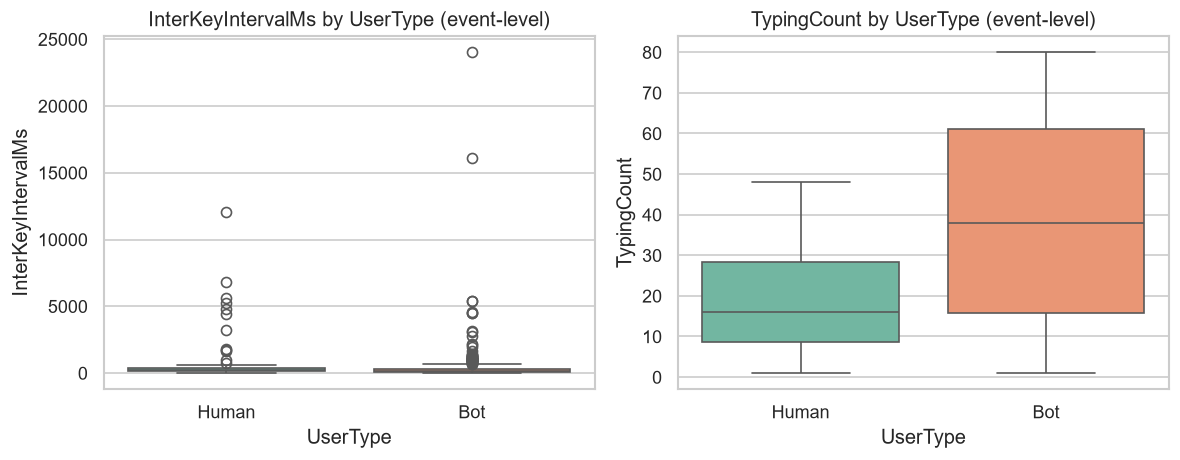


Session-level keyboard summary:
          n_key  interkey_median  interkey_iqr  interkey_cv
UserType                                                   
Bot        12.0            117.0       105.000        0.970
Human      22.0            185.0       220.375        2.476


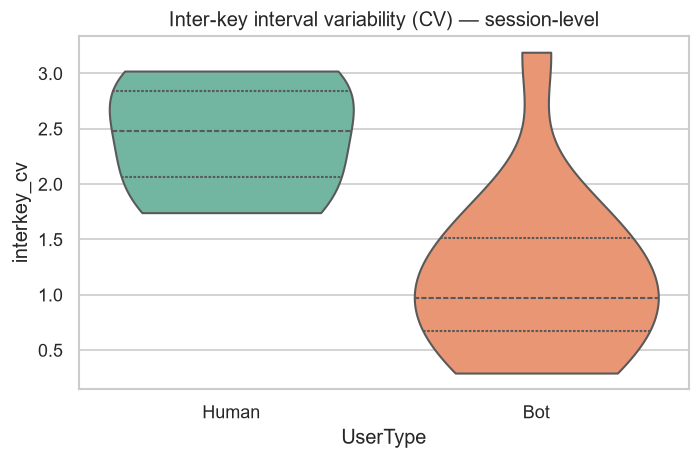

In [8]:
# 7. Keyboard/typing
key = df[df['EventType'].astype(str).str.lower().str.contains('key|type', regex=True)].copy()
for c in ['InterKeyIntervalMs','TypingCount']:
    if c in key.columns:
        key[c] = pd.to_numeric(key[c], errors='coerce')
print('Keyboard/typing events:', len(key))
print('Sessions with keyboard/typing:', key['SessionID'].nunique())
print(key.groupby('UserType').agg(n_events=('SessionID','size'), n_sessions=('SessionID','nunique')).to_string())

if len(key):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, col in zip(axes, ['InterKeyIntervalMs','TypingCount']):
        if col in key.columns and key[col].notna().any():
            d = key.dropna(subset=[col])
            sns.boxplot(data=d, x='UserType', y=col, ax=ax, palette='Set2')
            ax.set_title(f'{col} by UserType (event-level)')
        else:
            ax.set_visible(False)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'eda_keyboard_boxplots.png', bbox_inches='tight')
    plt.show()

    key_sess = key.groupby(['SessionID','UserType','BotType'], dropna=False).agg(
        n_key=('EventType','size'),
        interkey_median=('InterKeyIntervalMs','median'),
        interkey_iqr=('InterKeyIntervalMs', iqr),
        interkey_cv=('InterKeyIntervalMs', cv),
    ).reset_index()
    print('\nSession-level keyboard summary:')
    print(key_sess.groupby('UserType')[['n_key','interkey_median','interkey_iqr','interkey_cv']].median().round(3).to_string())
    key_sess.to_csv(ANALYSIS_DIR / 'eda_keyboard_session_summary.csv', index=False)

    if key_sess['interkey_cv'].notna().sum() > 1:
        fig, ax = plt.subplots(figsize=(6,4))
        sns.violinplot(data=key_sess, x='UserType', y='interkey_cv', inner='quartile', ax=ax, palette='Set2', cut=0)
        ax.set_title('Inter-key interval variability (CV) — session-level')
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'eda_keyboard_variability_violin.png', bbox_inches='tight')
        plt.show()
else:
    print('No keyboard/typing events found.')


**Interpretation:** Keyboard timing features (when present) may reflect different interaction rhythms, but event-level plots can be influenced by unequal event counts per session. Session-level summaries are used for comparisons, and no claim is made that typing timing alone is sufficient for bot detection.

## 8. Click behaviour

Click behaviour is examined using click events and click-related fields (e.g., `ClickIntervalMs`, `ClickCount`) where available.

Click events: 109
Sessions with clicks: 18
          n_events  n_sessions
UserType                      
Bot             58          13
Human           51           5


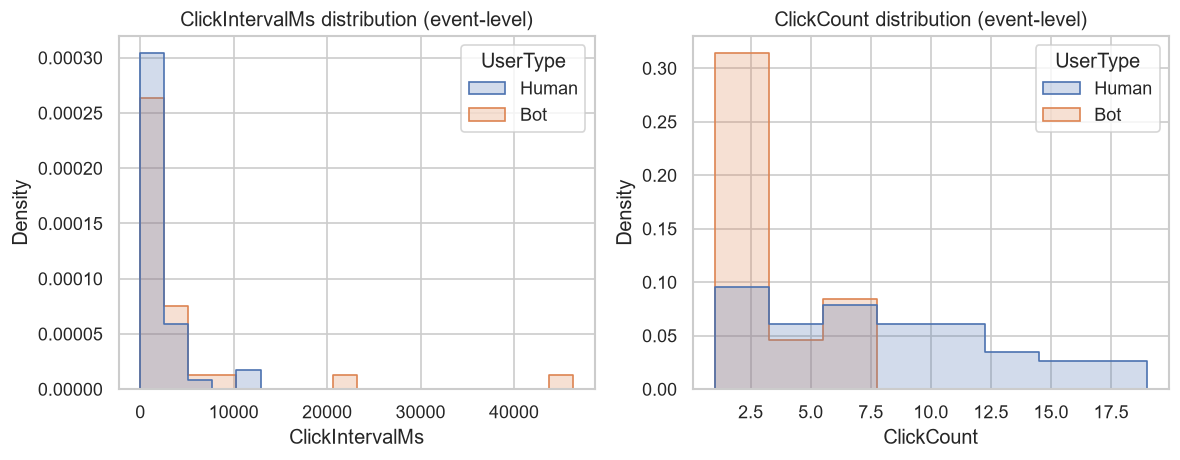


Session-level click summary:
          n_clicks  click_interval_median  click_interval_iqr
UserType                                                     
Bot            4.0                1254.25              1160.5
Human          8.0                1563.00              1336.0


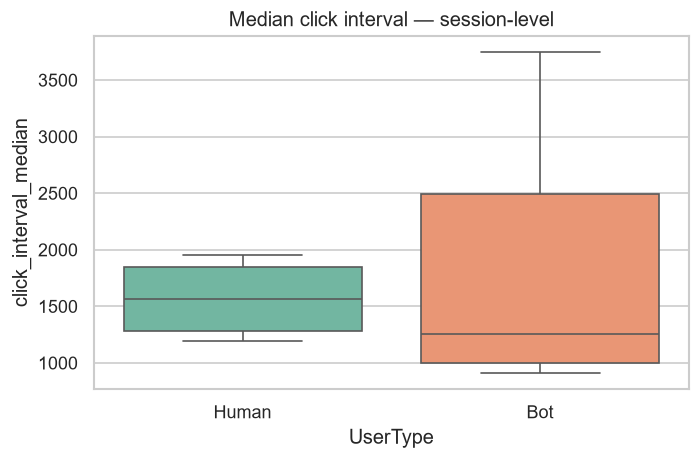

In [9]:
# 8. Click behaviour
click = df[df['EventType'].astype(str).str.lower().str.contains('click', regex=True)].copy()
for c in ['ClickIntervalMs','ClickCount']:
    if c in click.columns:
        click[c] = pd.to_numeric(click[c], errors='coerce')
print('Click events:', len(click))
print('Sessions with clicks:', click['SessionID'].nunique())
print(click.groupby('UserType').agg(n_events=('SessionID','size'), n_sessions=('SessionID','nunique')).to_string())

if len(click):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, col in zip(axes, ['ClickIntervalMs','ClickCount']):
        if col in click.columns and click[col].notna().any():
            d = click.dropna(subset=[col])
            sns.histplot(data=d, x=col, hue='UserType', kde=False, stat='density', common_norm=False, ax=ax, element='step')
            ax.set_title(f'{col} distribution (event-level)')
        else:
            ax.set_visible(False)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'eda_click_histograms.png', bbox_inches='tight')
    plt.show()

    click_sess = click.groupby(['SessionID','UserType','BotType'], dropna=False).agg(
        n_clicks=('EventType','size'),
        click_interval_median=('ClickIntervalMs','median'),
        click_interval_iqr=('ClickIntervalMs', iqr),
    ).reset_index()
    print('\nSession-level click summary:')
    print(click_sess.groupby('UserType')[['n_clicks','click_interval_median','click_interval_iqr']].median().round(3).to_string())
    click_sess.to_csv(ANALYSIS_DIR / 'eda_click_session_summary.csv', index=False)

    if click_sess['click_interval_median'].notna().sum() > 1:
        fig, ax = plt.subplots(figsize=(6,4))
        sns.boxplot(data=click_sess, x='UserType', y='click_interval_median', ax=ax, palette='Set2')
        ax.set_title('Median click interval — session-level')
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'eda_click_session_boxplot.png', bbox_inches='tight')
        plt.show()
else:
    print('No click events found.')


**Interpretation:** Click timing/count patterns are summarised descriptively. Differences in medians or spread may reflect task structure or automation style, but they are not, on their own, evidence of bot behaviour.

## 9. Scroll behaviour

Scroll behaviour is examined using scroll events and fields such as `ScrollDelta`, `ScrollSpeed`, and `ScrollCount` where available.

Scroll events: 82
Sessions with scroll: 14
          n_events  n_sessions
UserType                      
Bot             26          11
Human           56           3


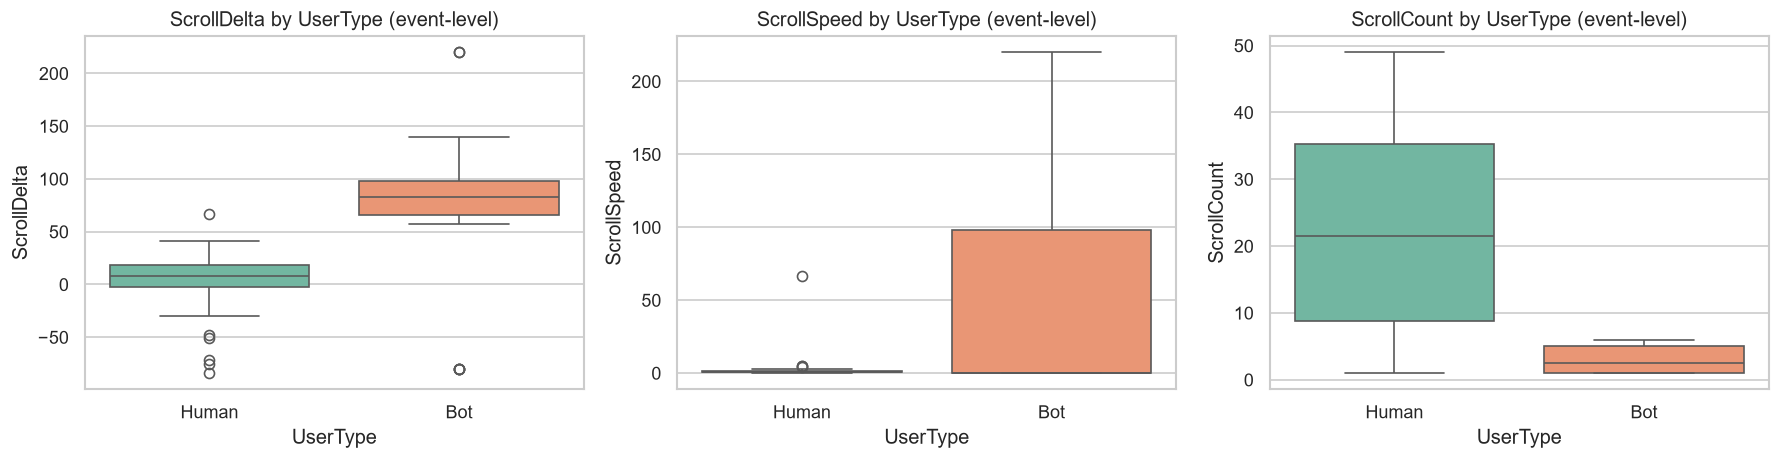


Session-level scroll summary:
          n_scroll  scroll_delta_median  scroll_speed_median
UserType                                                    
Bot            2.0                 67.0               28.444
Human          6.0                  9.6                0.941


In [10]:
# 9. Scroll behaviour
scroll = df[df['EventType'].astype(str).str.lower().str.contains('scroll', regex=True)].copy()
for c in ['ScrollDelta','ScrollSpeed','ScrollCount']:
    if c in scroll.columns:
        scroll[c] = pd.to_numeric(scroll[c], errors='coerce')
print('Scroll events:', len(scroll))
print('Sessions with scroll:', scroll['SessionID'].nunique())
print(scroll.groupby('UserType').agg(n_events=('SessionID','size'), n_sessions=('SessionID','nunique')).to_string())

if len(scroll):
    cols = [c for c in ['ScrollDelta','ScrollSpeed','ScrollCount'] if c in scroll.columns and scroll[c].notna().any()]
    if cols:
        fig, axes = plt.subplots(1, len(cols), figsize=(5*len(cols), 4))
        if len(cols) == 1:
            axes = [axes]
        for ax, col in zip(axes, cols):
            d = scroll.dropna(subset=[col])
            sns.boxplot(data=d, x='UserType', y=col, ax=ax, palette='Set2')
            ax.set_title(f'{col} by UserType (event-level)')
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'eda_scroll_boxplots.png', bbox_inches='tight')
        plt.show()

    scroll_sess = scroll.groupby(['SessionID','UserType','BotType'], dropna=False).agg(
        n_scroll=('EventType','size'),
        scroll_delta_median=('ScrollDelta','median'),
        scroll_speed_median=('ScrollSpeed','median'),
    ).reset_index()
    print('\nSession-level scroll summary:')
    print(scroll_sess.groupby('UserType')[['n_scroll','scroll_delta_median','scroll_speed_median']].median().round(3).to_string())
    scroll_sess.to_csv(ANALYSIS_DIR / 'eda_scroll_session_summary.csv', index=False)
else:
    print('No scroll events found.')


**Interpretation:** Scroll features describe interaction style during scrolling. Any observed group differences are exploratory and should be interpreted alongside sample sizes and event-type coverage.

## 10. Session duration

Session duration is compared at the session level using available duration fields (`SessionDurationMs`, with `ElapsedMs` as fallback).

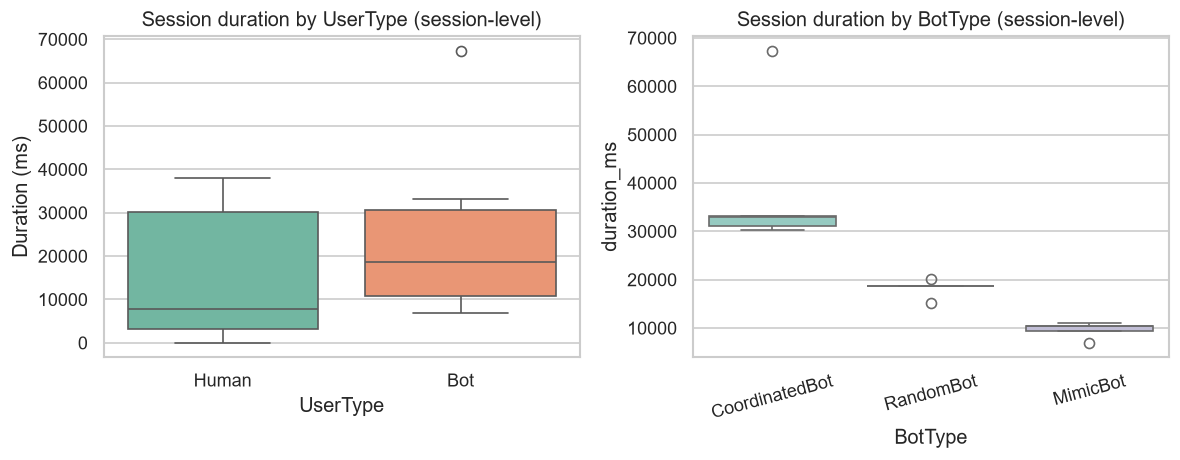

Session duration summary (ms):
          count   median     mean       std   min    max
UserType                                                
Bot          15  18660.0  22280.4  15375.88  6933  67328
Human         9   7755.0  15071.0  15259.56     0  38104

By BotType:
                count   median     mean       std
BotType                                          
CoordinatedBot      5  33026.0  38969.4  15899.92
MimicBot            5  10329.0   9621.8   1597.96
RandomBot           5  18660.0  18250.0   1828.29


In [11]:
# 10. Session duration
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=agg, x='UserType', y='duration_ms', ax=axes[0], palette='Set2')
axes[0].set_title('Session duration by UserType (session-level)')
axes[0].set_ylabel('Duration (ms)')

d = agg[agg['UserType']=='Bot']
sns.boxplot(data=d, x='BotType', y='duration_ms', ax=axes[1], palette='Set3')
axes[1].set_title('Session duration by BotType (session-level)')
axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_session_duration.png', bbox_inches='tight')
plt.show()

print('Session duration summary (ms):')
print(agg.groupby('UserType')['duration_ms'].agg(['count','median','mean','std','min','max']).round(2).to_string())
if len(d):
    print('\nBy BotType:')
    print(d.groupby('BotType')['duration_ms'].agg(['count','median','mean','std']).round(2).to_string())


**Interpretation:** Duration differences can reflect task design, scripted timing, or natural interaction pace. With small session counts per bot subtype, subtype patterns should be treated as descriptive observations rather than stable behavioural signatures.

## 11. Idle time

Idle time (`IdleMs`) is summarised per session (mean/median/standard deviation) to characterise pauses. Event-level idle values are not treated as independent session outcomes.

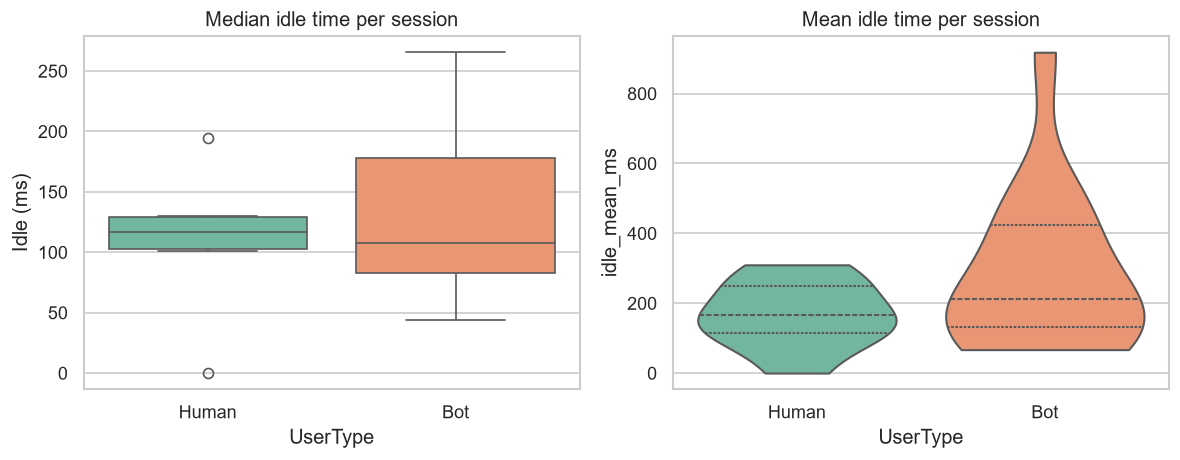

Idle time summary (session-level):
         idle_mean_ms                 idle_median_ms                idle_std_ms                
                count  median    mean          count median    mean       count  median    mean
UserType                                                                                       
Bot                15  211.59  277.00             15  107.5  129.30          15  244.51  551.83
Human               9  165.94  168.42              9  116.5  111.83           7  253.47  227.83


In [12]:
# 11. Idle time
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=agg, x='UserType', y='idle_median_ms', ax=axes[0], palette='Set2')
axes[0].set_title('Median idle time per session')
axes[0].set_ylabel('Idle (ms)')
sns.violinplot(data=agg, x='UserType', y='idle_mean_ms', inner='quartile', ax=axes[1], palette='Set2', cut=0)
axes[1].set_title('Mean idle time per session')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_idle_time.png', bbox_inches='tight')
plt.show()

print('Idle time summary (session-level):')
print(agg.groupby('UserType')[['idle_mean_ms','idle_median_ms','idle_std_ms']].agg(['count','median','mean']).round(2).to_string())


**Interpretation:** Idle-time summaries may indicate differences in pacing or waiting behaviour. These are descriptive signals to investigate further; they are not sufficient on their own to label a session as human or bot.

## 12. Navigation patterns

Navigation is examined using navigation events/counts where available. Because navigation data may be sparse, we report coverage before interpreting patterns.

Navigation events: 0
Sessions with navigation events: 0

Session-level navigation summary:
         navigation_events                 total_navigations                    
                     count sum median mean             count   sum median   mean
UserType                                                                        
Bot                     15   0    0.0  0.0                 4   4.0    1.0  1.000
Human                    9   0    0.0  0.0                 3  10.0    2.0  3.333


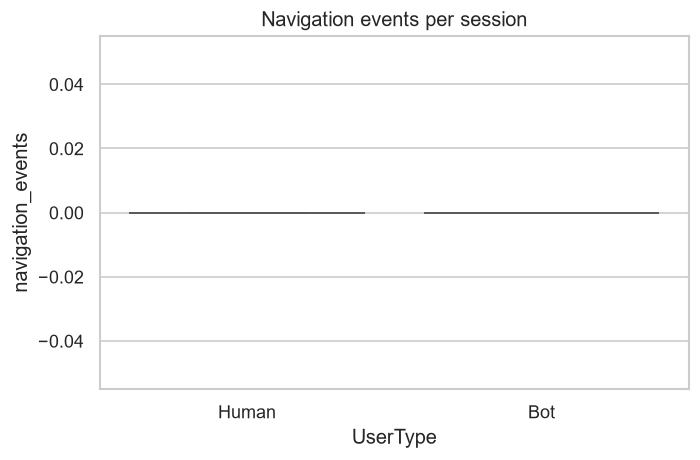

In [13]:
# 12. Navigation patterns
nav = df[df['EventType'].astype(str).str.lower().str.contains('nav', regex=True)].copy()
print('Navigation events:', len(nav))
print('Sessions with navigation events:', nav['SessionID'].nunique())
print('\nSession-level navigation summary:')
print(agg.groupby('UserType')[['navigation_events','total_navigations']].agg(['count','sum','median','mean']).round(3).to_string())

fig, ax = plt.subplots(figsize=(6,4))
sns.boxplot(data=agg, x='UserType', y='navigation_events', ax=ax, palette='Set2')
ax.set_title('Navigation events per session')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_navigation.png', bbox_inches='tight')
plt.show()


**Interpretation:** Navigation patterns depend on task flow and available instrumentation. If navigation events are infrequent, apparent differences may reflect sparse coverage rather than stable behavioural differences.

## 13. Behavioural variability

We quantify within-session variability using simple, interpretable statistics (standard deviation, IQR, coefficient of variation) computed from session-level aggregates and event-derived session summaries. Higher or lower variability is descriptive, not diagnostic.

Session-level variability-related summaries:
         n_events                        events_per_second                      duration_ms                              idle_mean_ms                            idle_std_ms                           
            count median    mean     std             count median   mean    std       count   median     mean        std        count   median     mean      std       count   median     mean      std
UserType                                                                                                                                                                                               
Bot            15   19.0  35.400  26.153                15  1.355  1.621  0.958          15  18660.0  22280.4  15375.884           15  211.588  277.004  230.831          15  244.508  551.833  835.344
Human           9   16.0  73.889  95.588                 8  4.581  4.646  3.203           9   7755.0  15071.0  15259.557            9  165.938  168.421   9

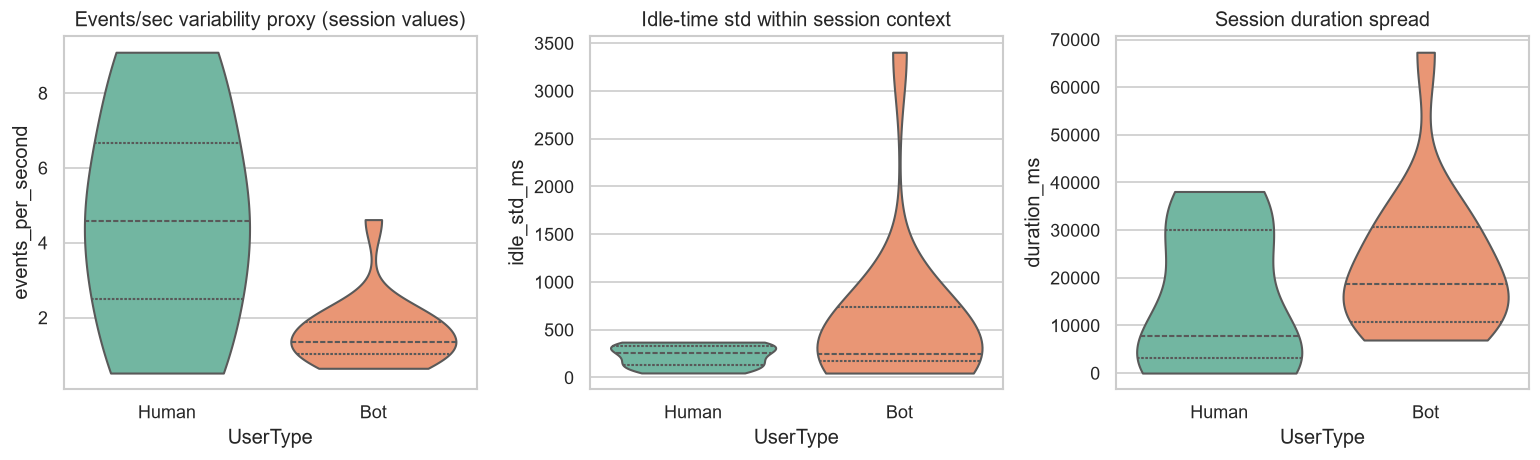

In [14]:
# 13. Behavioural variability (session-level)
var_cols = ['n_events','events_per_second','duration_ms','idle_mean_ms','idle_std_ms']
var_summary = agg.groupby('UserType')[var_cols].agg(['count','median','mean','std']).round(3)
print('Session-level variability-related summaries:')
print(var_summary.to_string())
var_summary.to_csv(ANALYSIS_DIR / 'eda_variability_summary.csv')

plot_df = agg[['UserType','BotType','events_per_second','idle_std_ms','duration_ms']].copy()
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, title in [
    (axes[0],'events_per_second','Events/sec variability proxy (session values)'),
    (axes[1],'idle_std_ms','Idle-time std within session context'),
    (axes[2],'duration_ms','Session duration spread'),
]:
    sns.violinplot(data=plot_df, x='UserType', y=col, inner='quartile', ax=ax, palette='Set2', cut=0)
    ax.set_title(title)
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_behavioural_variability.png', bbox_inches='tight')
plt.show()


**Interpretation:** Variability measures can highlight regularity or irregularity in interaction. Automated agents may appear more regular in some contexts, but humans can also be regular during constrained tasks; therefore variability should be investigated further with appropriate session-level features and validation.

## 14. Bot subtype comparisons (where sufficient observations exist)

We compare CoordinatedBot, RandomBot, and MimicBot descriptively. Each subtype has a small session count, so these comparisons are exploratory only.

Bot subtype session counts:
BotType
CoordinatedBot    5
MimicBot          5
RandomBot         5

Bot subtype session-level summary:
               n_events                      events_per_second                      duration_ms                              idle_median_ms                      
                  count median  mean     std             count median   mean    std       count   median     mean        std          count median   mean     std
BotType                                                                                                                                                          
CoordinatedBot        5   64.0  65.0   6.325                 5  1.908  1.801  0.431           5  33026.0  38969.4  15899.919              5  200.0  204.9  38.813
MimicBot              5   13.0  13.4   3.507                 5  1.355  1.417  0.383           5  10329.0   9621.8   1597.956              5   82.0   69.8  17.866
RandomBot             5   18.0  27.8  23.858              

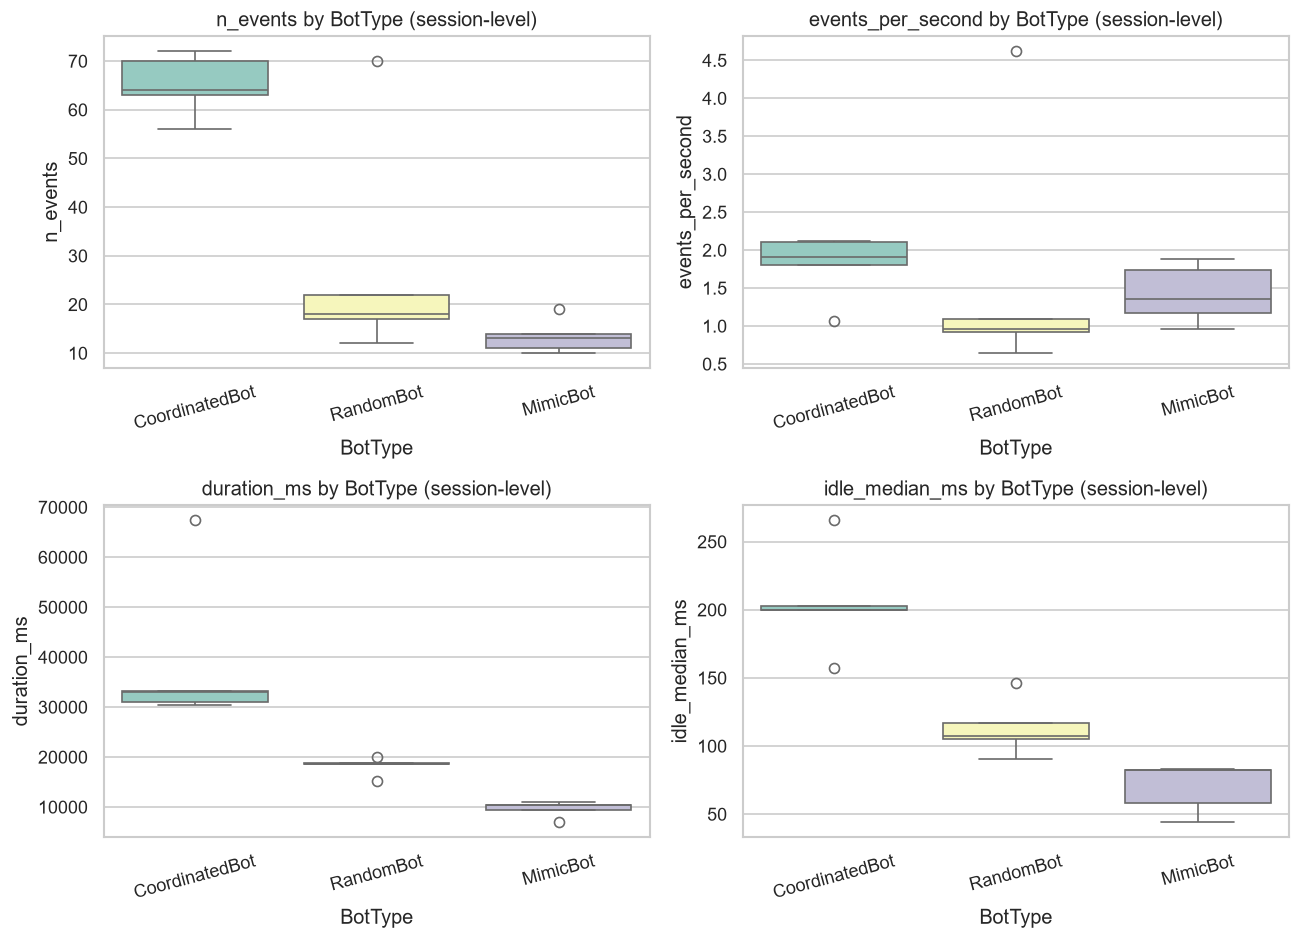

In [15]:
# 14. Bot subtype comparisons
bot_agg = agg[agg['UserType']=='Bot'].copy()
print('Bot subtype session counts:')
print(bot_agg.groupby('BotType')['SessionID'].nunique().to_string())

cols = ['n_events','events_per_second','duration_ms','idle_median_ms']
bot_summary = bot_agg.groupby('BotType')[cols].agg(['count','median','mean','std']).round(3)
print('\nBot subtype session-level summary:')
print(bot_summary.to_string())
bot_summary.to_csv(ANALYSIS_DIR / 'eda_bot_subtype_summary.csv')

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, cols):
    sns.boxplot(data=bot_agg, x='BotType', y=col, ax=ax, palette='Set3')
    ax.tick_params(axis='x', rotation=15)
    ax.set_title(f'{col} by BotType (session-level)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_bot_subtype_comparisons.png', bbox_inches='tight')
plt.show()


**Interpretation:** Subtype plots may suggest different pacing or activity profiles, but the number of sessions per subtype is small. These observations are hypotheses for later feature extraction and validation, not conclusions.

## 15. Correlation heatmap (numeric behavioural fields)

Correlations are computed over numeric event-level fields for descriptive context. Correlation does not imply causation, and event-level correlation can be affected by repeated events within sessions.

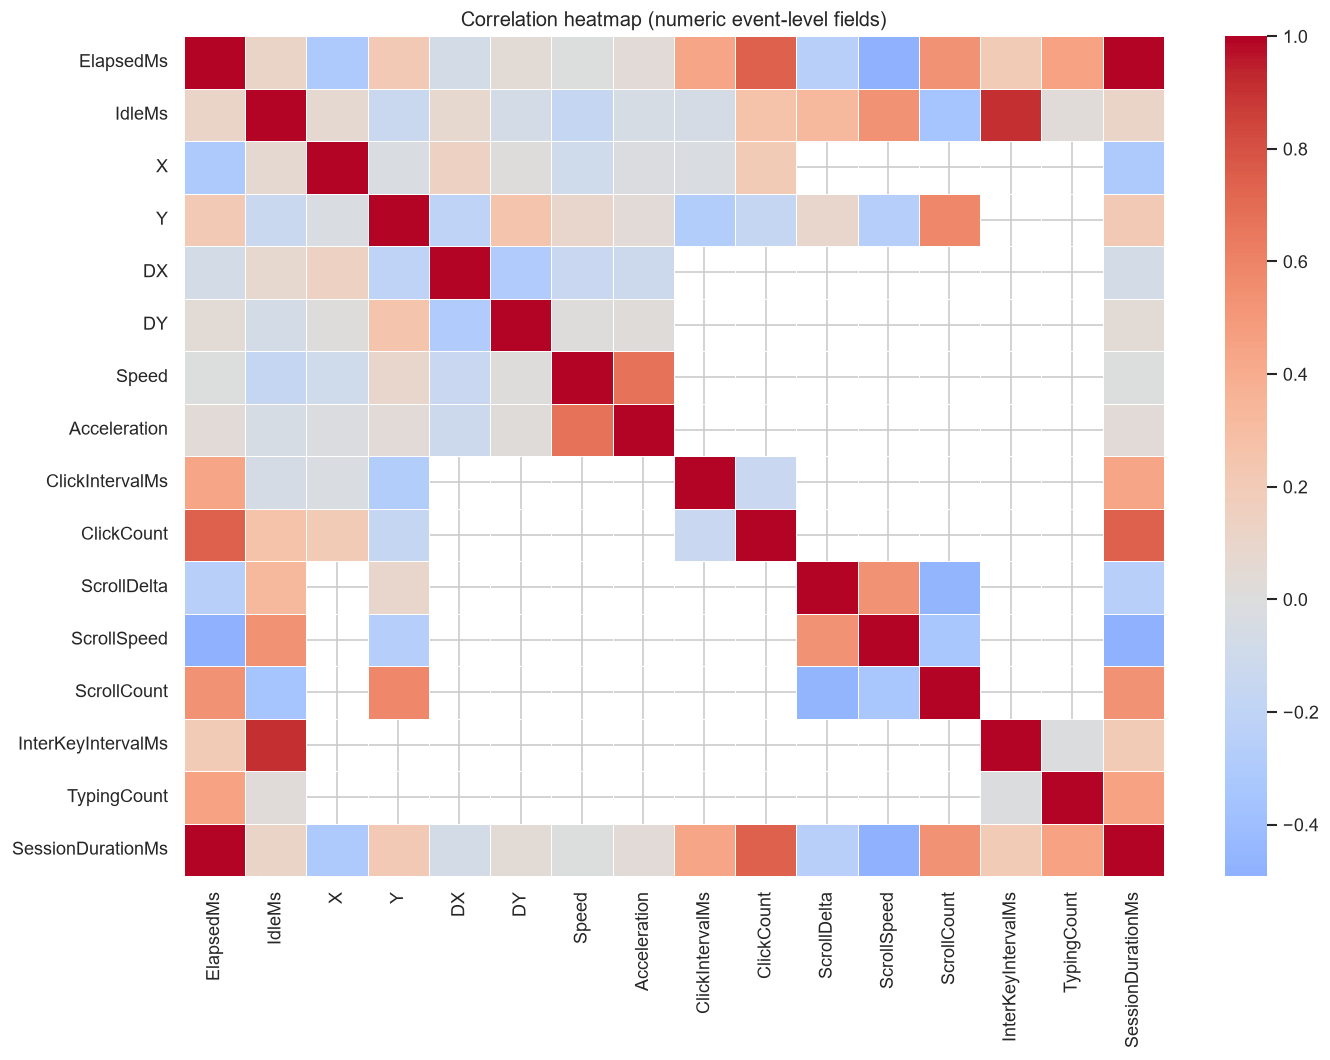

In [16]:
# 15. Correlation heatmap
num_cols = [c for c in ['ElapsedMs','IdleMs','X','Y','DX','DY','Speed','Acceleration','ClickIntervalMs','ClickCount','ScrollDelta','ScrollSpeed','ScrollCount','InterKeyIntervalMs','TypingCount','SessionDurationMs'] if c in df.columns]
num = df[num_cols].apply(pd.to_numeric, errors='coerce')
corr = num.corr(numeric_only=True)
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False, linewidths=0.3)
plt.title('Correlation heatmap (numeric event-level fields)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_correlation_heatmap.png', bbox_inches='tight')
plt.show()
corr.to_csv(ANALYSIS_DIR / 'eda_correlation_matrix.csv')


**Interpretation:** Strong correlations among related movement fields (e.g., displacement/speed/acceleration) are expected. Correlated features should be handled carefully during later feature engineering to avoid redundancy, but correlation alone does not indicate usefulness for bot detection.

## 16. Event distribution charts

Event-type distributions provide context about which behaviours are represented. We show both overall and per-group distributions.

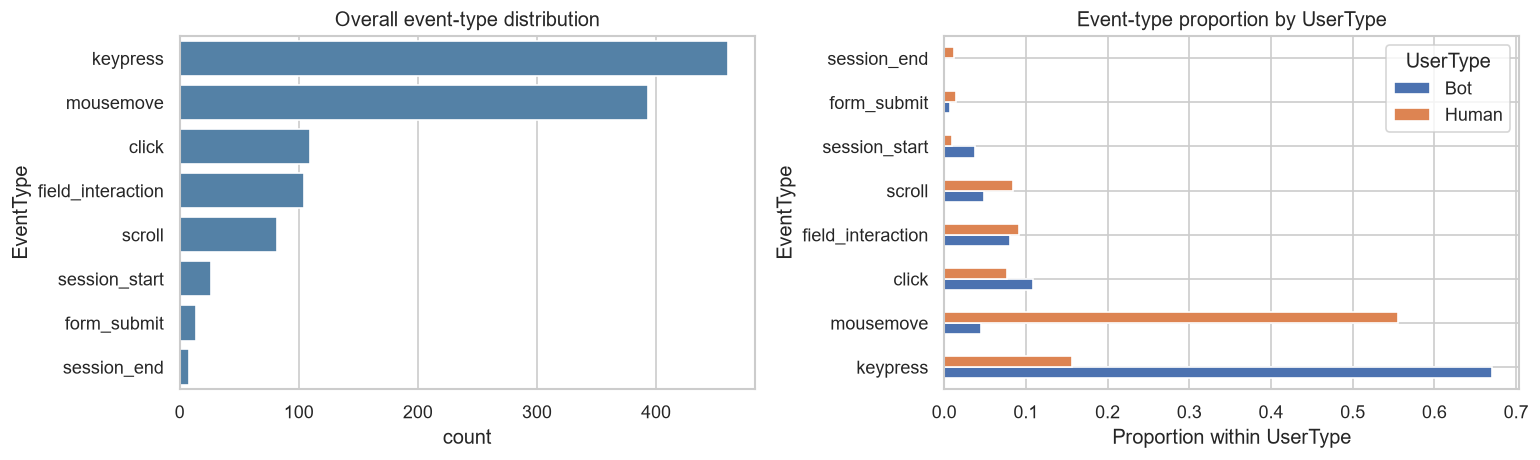

In [17]:
# 16. Event distribution charts
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = df['EventType'].value_counts().index
sns.countplot(data=df, y='EventType', order=order, ax=axes[0], color='steelblue')
axes[0].set_title('Overall event-type distribution')

ct = pd.crosstab(df['EventType'], df['UserType'], normalize='columns')
ct.loc[order.intersection(ct.index)].plot(kind='barh', stacked=False, ax=axes[1])
axes[1].set_title('Event-type proportion by UserType')
axes[1].set_xlabel('Proportion within UserType')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_event_distributions.png', bbox_inches='tight')
plt.show()
ct.to_csv(ANALYSIS_DIR / 'eda_event_type_by_usertype.csv')


**Interpretation:** Differences in event-type proportions may reflect interaction opportunities, collection conditions, or behavioural style. Because event counts are nested within sessions, these charts should be read together with session-level sample sizes.

## 17. Save EDA report

The report summarises observed patterns, potential behavioural differences, limitations, and features worth investigating further.

In [18]:
# 17. EDA report
hb = sample_hb.set_index('UserType')
human_ev = int(hb.loc['Human','n_events']) if 'Human' in hb.index else 'NA'
human_sess = int(hb.loc['Human','n_sessions']) if 'Human' in hb.index else 'NA'
bot_ev = int(hb.loc['Bot','n_events']) if 'Bot' in hb.index else 'NA'
bot_sess = int(hb.loc['Bot','n_sessions']) if 'Bot' in hb.index else 'NA'

bot_sub = sample_bot.copy()
bot_sub_lines = []
for _, r in bot_sub.iterrows():
    bot_sub_lines.append(f"- {r['BotType']}: {int(r['n_events'])} events across {int(r['n_sessions'])} sessions")

report = f'''# Exploratory Data Analysis Report (BotPrint)

## Scope
This report summarises exploratory analysis of `dataset/processed/cleaned_events.csv`.
EDA is descriptive: **visual or summary differences do not prove that a feature can distinguish humans and bots**.

## Sample sizes
- Human: {human_ev} events across {human_sess} sessions.
- Bot: {bot_ev} events across {bot_sess} sessions.
- Bot subtypes (session-level):
''' + chr(10).join(bot_sub_lines) + '''

Session-level conclusions in this EDA are based on session-level aggregates, not by treating individual events as independent sessions.

## Observed patterns (descriptive)
- **Event frequency:** session-level events-per-session and events-per-second summaries show how active sessions are; distributions overlap and should be interpreted with session counts in mind.
- **Mouse movement:** event-level `Speed`/`Acceleration`/displacement distributions and session-level speed variability (CV/IQR) were examined where mouse events exist.
- **Keyboard typing:** inter-key timing/count fields were summarised when present; coverage depends on keyboard event availability.
- **Click behaviour:** click intervals/counts were summarised when present; session-level medians reduce the influence of unequal event counts.
- **Scroll behaviour:** scroll delta/speed/count were examined where scroll events exist.
- **Session duration:** compared at session level; bot subtypes show descriptive differences but small subtype samples.
- **Idle time:** session-level mean/median/standard deviation of `IdleMs` characterise pauses.
- **Navigation patterns:** navigation coverage may be limited; sparse navigation should not be over-interpreted.
- **Behavioural variability:** interpretable within-session variability measures (std/IQR/CV) were used to describe regularity/irregularity.

## Potential behavioural differences to investigate further
These are hypotheses, not confirmed discriminators:
- Timing regularity (mouse speed variability, inter-key interval variability, click interval variability).
- Activity pacing (events per second, idle-time distribution) at session level.
- Movement dynamics (speed/acceleration distributions) aggregated per session.
- Bot subtype differences (CoordinatedBot vs RandomBot vs MimicBot) using larger samples and controlled comparisons.

## Limitations
- **Small session counts**, especially per bot subtype (5 sessions each), limit statistical stability and generalisability.
- **Event dependence:** events are nested within sessions; event-level plots can over-represent sessions with many events.
- **Coverage differences:** not all sessions contain all event types (mouse/keyboard/click/scroll/navigation).
- **Missing values are structural** for some event types in the raw/cleaned event schema; summaries use available non-missing values and report counts where relevant.
- **Collection/context effects:** observed differences may partly reflect task design, instrumentation, or scripted scenarios rather than intrinsic human/bot behaviour.
- **No causal claims:** EDA identifies patterns worth testing, not causal mechanisms.

## Features worth investigating further (session-level)
- Mouse: median/IQR/CV of speed and acceleration; path-length proxies from DX/DY; movement burstiness.
- Keyboard: median/IQR/CV of inter-key intervals; typing-event rate; pause patterns.
- Click: median/IQR of click intervals; click rate; double-click/burst indicators if derivable.
- Scroll: median scroll delta/speed; scroll frequency and direction changes.
- Temporal: session duration, idle-time mean/median/std, active-time ratio.
- Navigation: navigation count/rate where available.
- Cross-modal variability: compare regularity across modalities within the same session.

## Reproducibility and data integrity
- Analysis uses `dataset/processed/cleaned_events.csv` produced by the preprocessing pipeline.
- Original raw data in `dataset/raw/` was not modified.
- Labels/identifiers are not used as behavioural features in downstream modelling; EDA uses `UserType`/`BotType` only for descriptive grouping.
'''
(ANALYSIS_DIR / 'eda_report.md').write_text(report, encoding='utf-8')
print('Saved:', ANALYSIS_DIR / 'eda_report.md')


Saved: C:\My KS\Research\BotPrint-Research\reports\analysis\eda_report.md


## 18. Summary

This EDA provides a descriptive baseline for BotPrint behavioural signals. It highlights candidate session-level features (timing, movement dynamics, pacing, variability, and navigation where available) while explicitly accounting for sample sizes, event-vs-session units, and the limits of visual/statistical description. The next steps are feature extraction and interpretable session-level fingerprint generation, followed by careful validation without data leakage.